# Discrete Distributions {#sec-discrete-random-variables}

Open in Google Colab (class): [![Open in Colab (class)](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}class/{{< env QUARTO_DOCUMENT_FILE >}}))
Open in Google Colab (full): [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}{{< env QUARTO_DOCUMENT_FILE >}})

:::{#exr-coin-game .ex-class}

$$
\Omega = \{HH, HT, TH, TT\}
$$

where H denotes heads and T denotes tails. Let $w$ be an outcome (one of the four elements) in the sample space $\Omega$. The payoff function $X(w)$ is defined as follows:

$$
X(\omega) = \begin{cases}
0 & \text{if } \omega = TT \\
1 & \text{if } \omega = HT \text{ or } \omega = TH \text{ or } \omega = HH \\
\end{cases}
$$

:::

Text(0, 0.5, 'Probability')

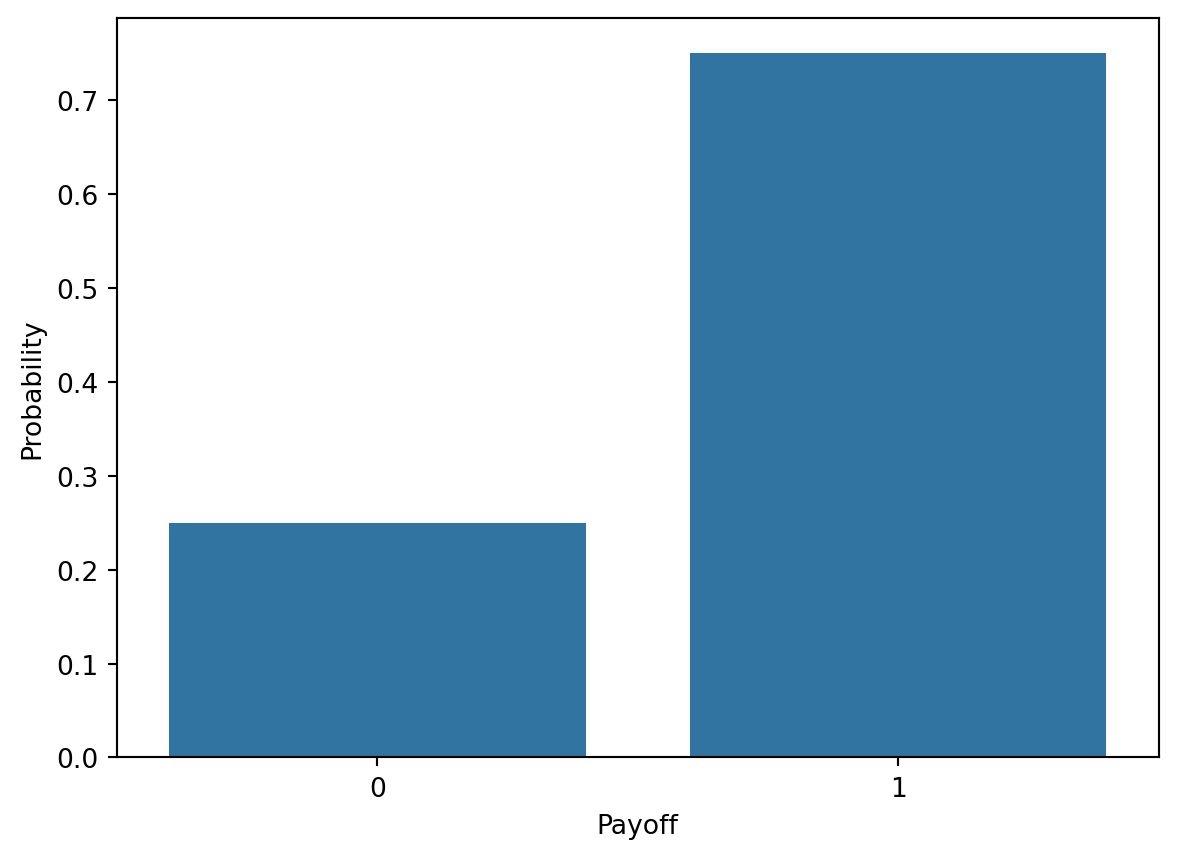

In [1]:

#| label: fig-coins-pmf-plot
#| caption: Plot of the probability mass function of the payoff of the coin game.
#ex-class

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


sns.barplot(x=[0, 1], y=[1/4, 3/4])
plt.xlabel('Payoff')
plt.ylabel('Probability')

In [2]:
#ex-class
# Simulate the game

# We use 0 to represent heads and 1 to represent tails
coins_game = np.random.choice([0, 1], size=[1000, 2])
df_coins = pd.DataFrame(coins_game, columns=['toss1', 'toss2'])
df_coins.head()

,toss1,toss2
0,0,1
1,1,0
2,0,0
3,1,1
4,0,1


In [3]:
# The payoff is equal to 1 EUR if there is at least one head
# x-class

df_coins["payoff"] = ((df_coins["toss1"] + df_coins["toss2"]) > 0).astype(int)
df_coins.head()

,toss1,toss2,payoff
0,0,1,1
1,1,0,1
2,0,0,0
3,1,1,1
4,0,1,1


In [4]:
#ex-class

# Now let's count how many times we won 1 EUR and how many times we
# were left empty-handed

df_coins["payoff"].value_counts()

payoff
1    756
0    244
Name: count, dtype: int64

In [5]:
#ex-class
df_coins["payoff"].value_counts(normalize=True)

payoff
1    0.756
0    0.244
Name: proportion, dtype: float64

Text(9.066666666666666, 0.5, 'Proportions')

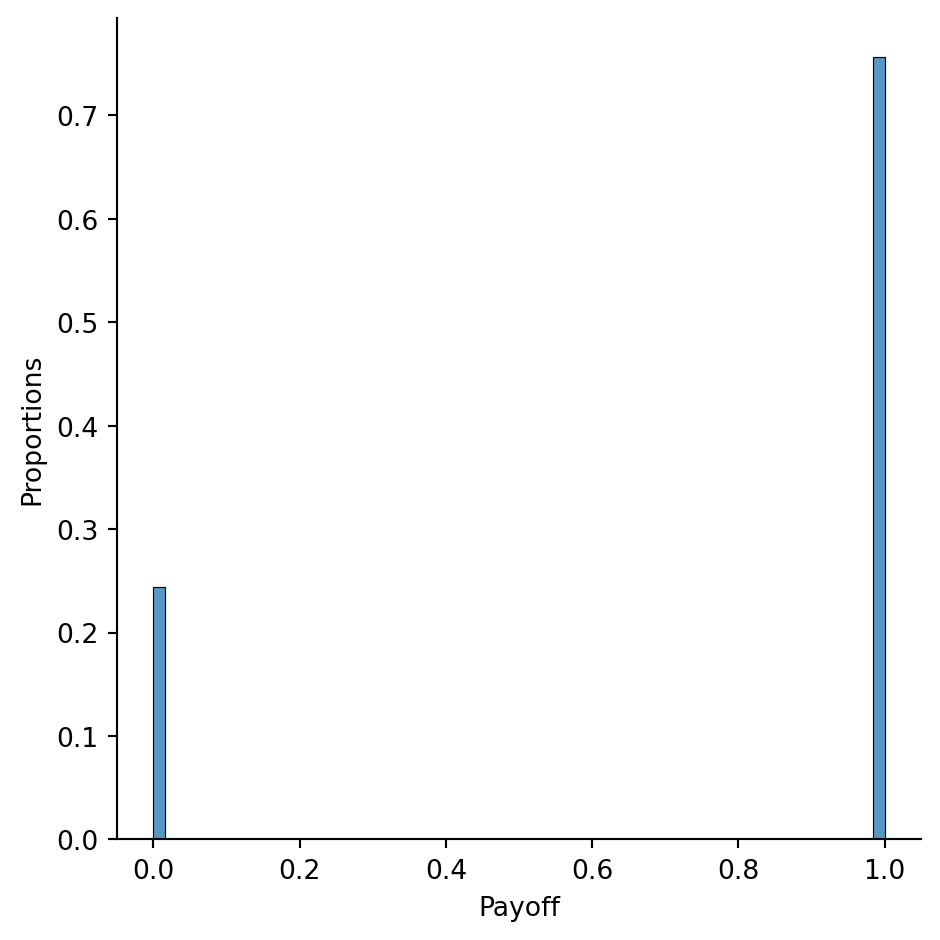

In [6]:
#| label: fig-coins-epmf-simulated
#| caption: Empirical probability mass function of the payoff of the coin game.
#ex-class

sns.displot(x="payoff", data=df_coins, stat='probability')

plt.xlabel('Payoff')
plt.ylabel('Proportions')

:::{#exr-pmf .ex-class}

## Exercise (Probability Mass Function)

Which of the following functions is not a valid probability mass function?

$$
f_1(x) = \begin{cases}
\frac{1}{4} & x = 0, 1, 2, 3, 4 \\
0 & \text{otherwise}
\end{cases}
$$

$$
f_2(x) = 
\begin{cases}
\frac{1}{2} & x = 0, 1 \\
-1 & \text{otherwise}
\end{cases}
$$

$$ 
f_3(x) = \begin{cases}
\frac{1}{4} & \text{if } x = 0 \\
\frac{1}{2} & \text{if } x = -1 \\
0 & \text{otherwise}
\end{cases}
$$

$$ 
f_4(x) = \begin{cases}
\frac{1}{4} & \text{if } x = 0 \\
\frac{1}{2} & \text{if } x = -1 \\
\frac{1}{4} & \text{if } x = 3.5 \\
0 & \text{otherwise}
\end{cases}
$$
:::

:::{#exr-pmf .ex-class}
## PMF

Construct the PMF of a random variable $X$ that is the sum of the outcomes of rolling two fair four-sided dice. The sample space of the experiment is

$$
\Omega = \left\{\begin{array}{cccc}
1,1 & 1,2 & 1,3 & 1,4 \\
2,1 & 2,2 & 2,3 & 2,4 \\
3,1 & 3,2 & 3,3 & 3,4 \\
4,1 & 4,2 & 4,3 & 4,4 \\
\end{array}\right\}
$$

:::

:::{#exr-pmf-team .ex-class}
## Soccer Games

Your hobby soccer team will play 2 games this weekend and has a probability of 0.4 of not losing the first game and 0.7 of not losing the second game. 
If it does not lose a particular game, the team is equally likely to win or tie. 
The team will receive 2 points for a win, 1 for a tie, and 0 for a loss. 
Construct the PMF of the number of points that the team earns over the weekend. 
Assume that the two games are independent.

:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

Let $X_1$ be the points from the first game, $X_2$ the points from the second game, and $X = X_1 + X_2$ the total number of points over the weekend. In each game we can win 0, 1 or 2 points, so from two games we can win anything between 0 and 4 points.

**Step 1: the distribution of each game.** The problem gives us three conditions:

1. A win gives 2 points, a tie 1 point, and a loss 0 points.
2. The probability of *not losing* (remember, this is not the same as winning as there can also be a tie) is $0.4$ in the first game and $0.7$ in the second. Losing is the complement, so $P(\text{loss}) = 1 - 0.4 = 0.6$ in the first game and $1 - 0.7 = 0.3$ in the second.
3. If the team does not lose, a win and a tie are equally likely, so each gets half of the probability of not losing: $0.4 / 2 = 0.2$ in the first game and $0.7 / 2 = 0.35$ in the second.

| Result | Points | $P$ in game 1: $f_{X_1}$ | $P$ in game 2: $f_{X_2}$ |
|---|---|---|---|
| Loss | 0 | $1 - 0.4 = 0.60$ | $1 - 0.7 = 0.30$ |
| Tie | 1 | $0.4 / 2 = 0.20$ | $0.7 / 2 = 0.35$ |
| Win | 2 | $0.4 / 2 = 0.20$ | $0.7 / 2 = 0.35$ |
| Total | | $1.00$ | $1.00$ |

**Step 2: the events for each total.** Write $L_1, T_1, W_1$ for losing, tying, and winning the first game (G1) and $L_2, T_2, W_2$ for the second game (G2). For each possible total we list the results of the two games that produce it. Two rules turn the events into probabilities:

- **AND: multiply.** The games are *independent* by assumption (the fourth condition), so, for example, $P(L_1 \text{ and } T_2) = P(L_1) \cdot P(T_2) = 0.60 \cdot 0.35$.
- **OR: add.** The combinations in one row cannot happen at the same time (disjoint), so the probability of the row is the sum of their probabilities.

| Points $x$ | Event $\{X = x\}$ | $P(X = x)$ |
|---|---|---|
| 0 | lose G1 **and** lose G2 | $0.60 \cdot 0.30 = 0.18$ |
| 1 | (lose G1 **and** tie G2) **or** (tie G1 **and** lose G2) | $0.60 \cdot 0.35 + 0.20 \cdot 0.30 = 0.21 + 0.06 = 0.27$ |
| 2 | (lose G1 **and** win G2) **or** (tie G1 **and** tie G2) **or** (win G1 **and** lose G2) | $0.60 \cdot 0.35 + 0.20 \cdot 0.35 + 0.20 \cdot 0.30 = 0.21 + 0.07 + 0.06 = 0.34$ |
| 3 | (tie G1 **and** win G2) **or** (win G1 **and** tie G2) | $0.20 \cdot 0.35 + 0.20 \cdot 0.35 = 0.07 + 0.07 = 0.14$ |
| 4 | win G1 **and** win G2 | $0.20 \cdot 0.35 = 0.07$ |
| Total | | $1.00$ |

The probabilities are non-negative and sum to one, so this is a valid PMF. The most likely result is 2 points.

**Derivation with convolution.** $X$ is the sum of two independent random variables, so we can also obtain its PMF with the convolution formula from @sec-distribution-of-sum:

$$
f_X(s) = \sum_{k} f_{X_1}(k) f_{X_2}(s - k).
$$

The sum runs over the possible values of the first game, $k \in \{0, 1, 2\}$. A term is zero whenever $s - k$ is not a possible number of points in the second game (not one of $0, 1, 2$).

$$
\begin{align*}
f_X(0) & = f_{X_1}(0) f_{X_2}(0) = 0.60 \cdot 0.30 = 0.18 \\
f_X(1) & = f_{X_1}(0) f_{X_2}(1) + f_{X_1}(1) f_{X_2}(0) = 0.60 \cdot 0.35 + 0.20 \cdot 0.30 = 0.27 \\
f_X(2) & = f_{X_1}(0) f_{X_2}(2) + f_{X_1}(1) f_{X_2}(1) + f_{X_1}(2) f_{X_2}(0) = 0.21 + 0.07 + 0.06 = 0.34 \\
f_X(3) & = f_{X_1}(1) f_{X_2}(2) + f_{X_1}(2) f_{X_2}(1) = 0.20 \cdot 0.35 + 0.20 \cdot 0.35 = 0.14 \\
f_X(4) & = f_{X_1}(2) f_{X_2}(2) = 0.20 \cdot 0.35 = 0.07
\end{align*}
$$

This is the same PMF as in Step 2. Each term $f_{X_1}(k) f_{X_2}(s - k)$ is one "AND" event from the table (the first game gives $k$ points **and** the second game gives the remaining $s - k$), and the sum over $k$ is the "OR" that joins them. The convolution formula does exactly what we did by hand.

:::

In [7]:
# Check the solution: the PMF of a sum of independent variables is the convolution of their PMFs

import numpy as np

points_game_1 = np.array([0.60, 0.20, 0.20])   # P(0), P(1), P(2) points in game 1
points_game_2 = np.array([0.30, 0.35, 0.35])   # P(0), P(1), P(2) points in game 2

pmf_total_points = np.convolve(points_game_1, points_game_2)
for points, probability in enumerate(pmf_total_points):
    print(f"P(X = {points}) = {probability:.2f}")

P(X = 0) = 0.18
P(X = 1) = 0.27
P(X = 2) = 0.34
P(X = 3) = 0.14
P(X = 4) = 0.07


## Expected Value


Take the example in @exr-pmf-team and ask the question. If you play the two games 100 times (about 2 years worth of weekends), what average score (per weekend) do you expect? In about 18 of the 100 weekends the team scores 0 points, in about 27 weekends it scores 1 point, in about 34 weekends 2 points, in about 14 weekends 3 points, and in about 7 weekends 4 points. These numbers come from the PMF: in 100 weekends we expect $100 \cdot P(X = x)$ weekends with $x$ points.

| Points $x$ | $f(x) = P(X = x)$ | Expected number of weekends (out of 100) | Points from these weekends |
|---|---|---|---|
| 0 | $0.18$ | 18 | $18 \cdot 0 = 0$ |
| 1 | $0.27$ | 27 | $27 \cdot 1 = 27$ |
| 2 | $0.34$ | 34 | $34 \cdot 2 = 68$ |
| 3 | $0.14$ | 14 | $14 \cdot 3 = 42$ |
| 4 | $0.07$ | 7 | $7 \cdot 4 = 28$ |
| Total | $1.00$ | 100 | $165$ |

Over the 100 weekends the team collects about $165$ points in total, so the average per weekend is the total divided by the number of weekends:

$$
\text{average} = \frac{18 \cdot 0 + 27 \cdot 1 + 34 \cdot 2 + 14 \cdot 3 + 7 \cdot 4}{100} = \frac{165}{100} = 1.65.
$$

Splitting the fraction into one term per value shows what this average really is: each value is weighted by the fraction of weekends in which it occurs.

$$
\text{average} = \frac{18}{100} \cdot 0 + \frac{27}{100} \cdot 1 + \frac{34}{100} \cdot 2 + \frac{14}{100} \cdot 3 + \frac{7}{100} \cdot 4 = 1.65.
$$

The fractions $\frac{18}{100}, \frac{27}{100}, \ldots, \frac{7}{100}$ are exactly the probabilities $P(X = 0), P(X = 1), \ldots, P(X = 4)$. The number of weekends (100) cancels, so we would get the same answer for 50 or 1000 weekends: the average is the sum of the values weighted by their probabilities. Note that $1.65$ is not a score the team can actually get in one weekend; it is a long-run average.

:::{#def-expected-value .ex-class}
## Expected Value

For a discrete random variable $X$ with PMF $f(x)$, the expected value (or mean) of $X$ is

$$
E(X) = \sum_x x f(x),
$$

where the sum runs over all possible values $x$ of $X$.

::::{.video title="Video: The Expected Value as a Center of Mass (click to expand)"}
:::{#fig-video-discrete-expected-value}
{{< video ./figures/discrete/ExpectedValueCenterOfMass_chapters.mp4 >}}

The Expected Value as a Center of Mass
:::
::::


:::

For the soccer team $x$ runs from 0 to 4 and $f(x)$ gives the probability of each score.

$$
\begin{align*}
E(X) & = 0\cdot f(0) + 1 f(1) + 2 f(2) + 3 f(3) + 4 f(4) \\
E(X) & = 0 \cdot 0.18 + 1 \cdot 0.27 + 2 \cdot 0.34 + 3 \cdot 0.14 + 4 \cdot 0.07 = 1.65 \text{ points per weekend}.
\end{align*}
$$

In 100 real weekends the counts will not be exactly 18, 27, 34, 14, and 7, because the results are random, so the actual average will be close to $1.65$ but usually not equal to it. The law of large numbers (@thm-wlln) makes precise in what sense the average approaches $E(X)$ as the number of weekends grows.



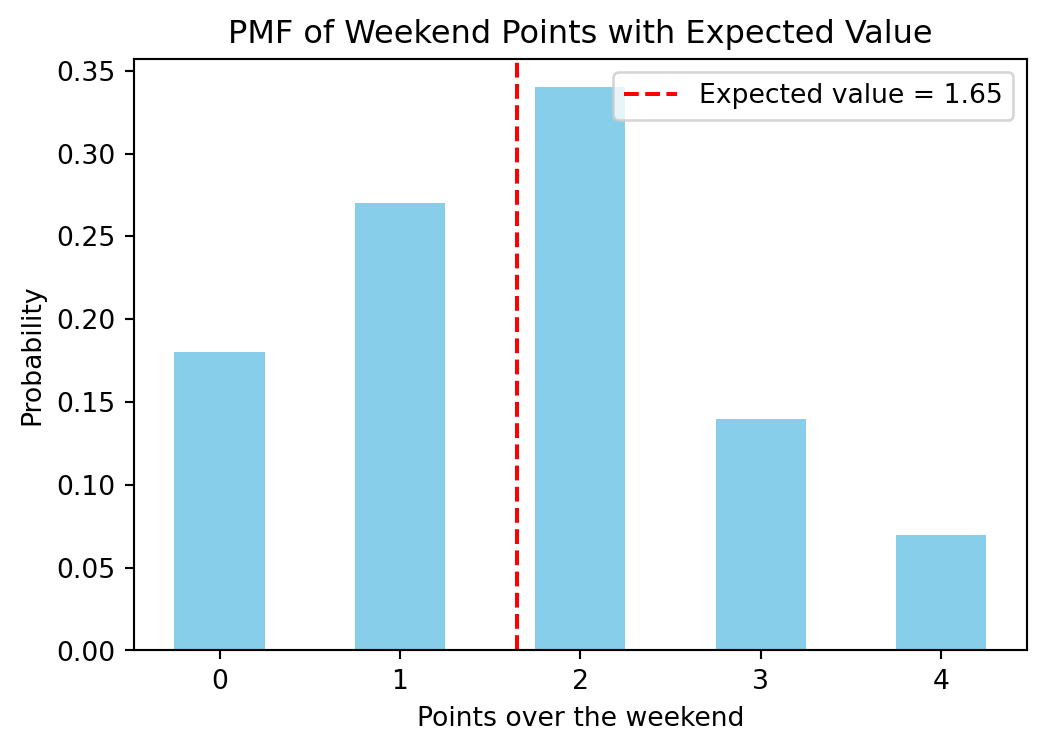

In [8]:
#| label: fig-soccer-pmf-expected-value
#| fig-cap: PMF of the number of points the soccer team earns over a weekend, with the expected value (dashed line).

# Plot the expected value of the soccer weekend in
# a plot of the PMF

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# PMF of the total points over the weekend (from the solution of the soccer exercise)
pmf_soccer = pd.DataFrame({
    'points': [0, 1, 2, 3, 4],
    'probability': [0.18, 0.27, 0.34, 0.14, 0.07]
})

# Compute the expected value: sum of the values weighted by their probabilities
expected_points = (pmf_soccer['points'] * pmf_soccer['probability']).sum()

plt.figure(figsize=(6, 4))
plt.bar(pmf_soccer['points'], pmf_soccer['probability'], color='skyblue', width=0.5)
plt.xlabel('Points over the weekend')
plt.ylabel('Probability')

# Add a vertical line for the expected value
plt.axvline(expected_points, color='red', linestyle='--', label=f'Expected value = {expected_points:.2f}')

plt.legend()
plt.title('PMF of Weekend Points with Expected Value')
plt.show()

## Variance


In [9]:
#ex-class

x2 = np.array([-1, 2.5])
p_x2 = np.array([0.5, 0.5])

# Compute the expected value of the second game

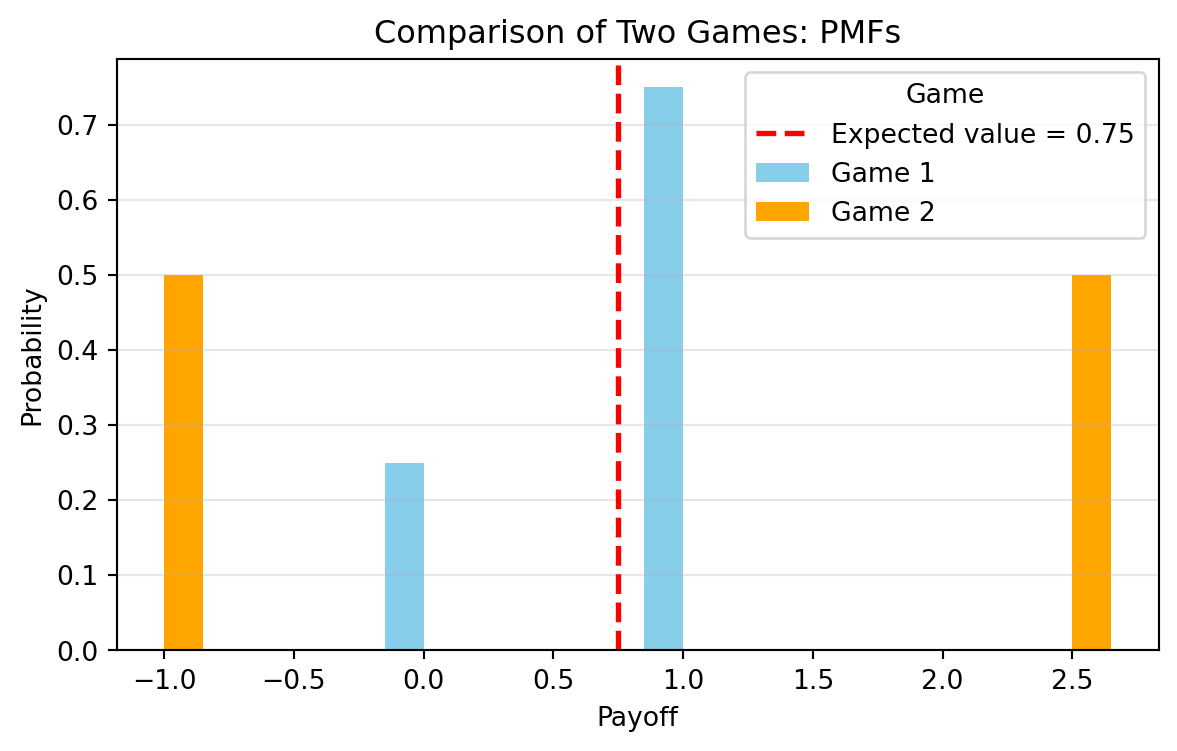

In [10]:
#ex-class

# Plot the first and the second PMF in the same plot

# First PMF: the coin game (payoff 1 with probability 0.75, 0 with probability 0.25)
pmf1 = pd.DataFrame({
    'payoff': [0, 1],
    'probability': [0.25, 0.75],
    'game': 'Game 1'
})

# Second PMF
pmf2 = pd.DataFrame({
    'payoff': [-1, 2.5],
    'probability': [0.5, 0.5],
    'game': 'Game 2'
})

expected_value_2 = (x2 * p_x2).sum()

fig, ax = plt.subplots(figsize=(7,4))

# Plot bars for each game manually with proper numeric positioning
width = 0.15
game1_data = pmf1[pmf1['game'] == 'Game 1']
game2_data = pmf2[pmf2['game'] == 'Game 2']

ax.bar(game1_data['payoff'] - width/2, game1_data['probability'], width=width, label='Game 1', color='skyblue')
ax.bar(game2_data['payoff'] + width/2, game2_data['probability'], width=width, label='Game 2', color='orange')

# Add expected value line
ax.axvline(expected_value_2, color='red', linestyle='--', linewidth=2, label=f'Expected value = {expected_value_2:.2f}')

ax.set_xlabel('Payoff')
ax.set_ylabel('Probability')
ax.set_title('Comparison of Two Games: PMFs')
ax.legend(title='Game')
ax.grid(axis='y', alpha=0.3)
plt.show()

::{#def-variance .ex-class}
## Variance

For a discrete random variable $X$ with PMF $f(x)$, the variance is defined as

$$
Var(X) = E((X - E(X))^2) = \sum_x (x - E(X))^2 f(x)
$$

The square root of the variance is called the **standard deviation**.

$$
SD(X) = \sqrt{Var(X)}
$$

:::


## Variance and Risk

The second game from the previous exercise is more risky because the payoffs are more variable. To see this, let's say 1000 persons play both games 10 times each.

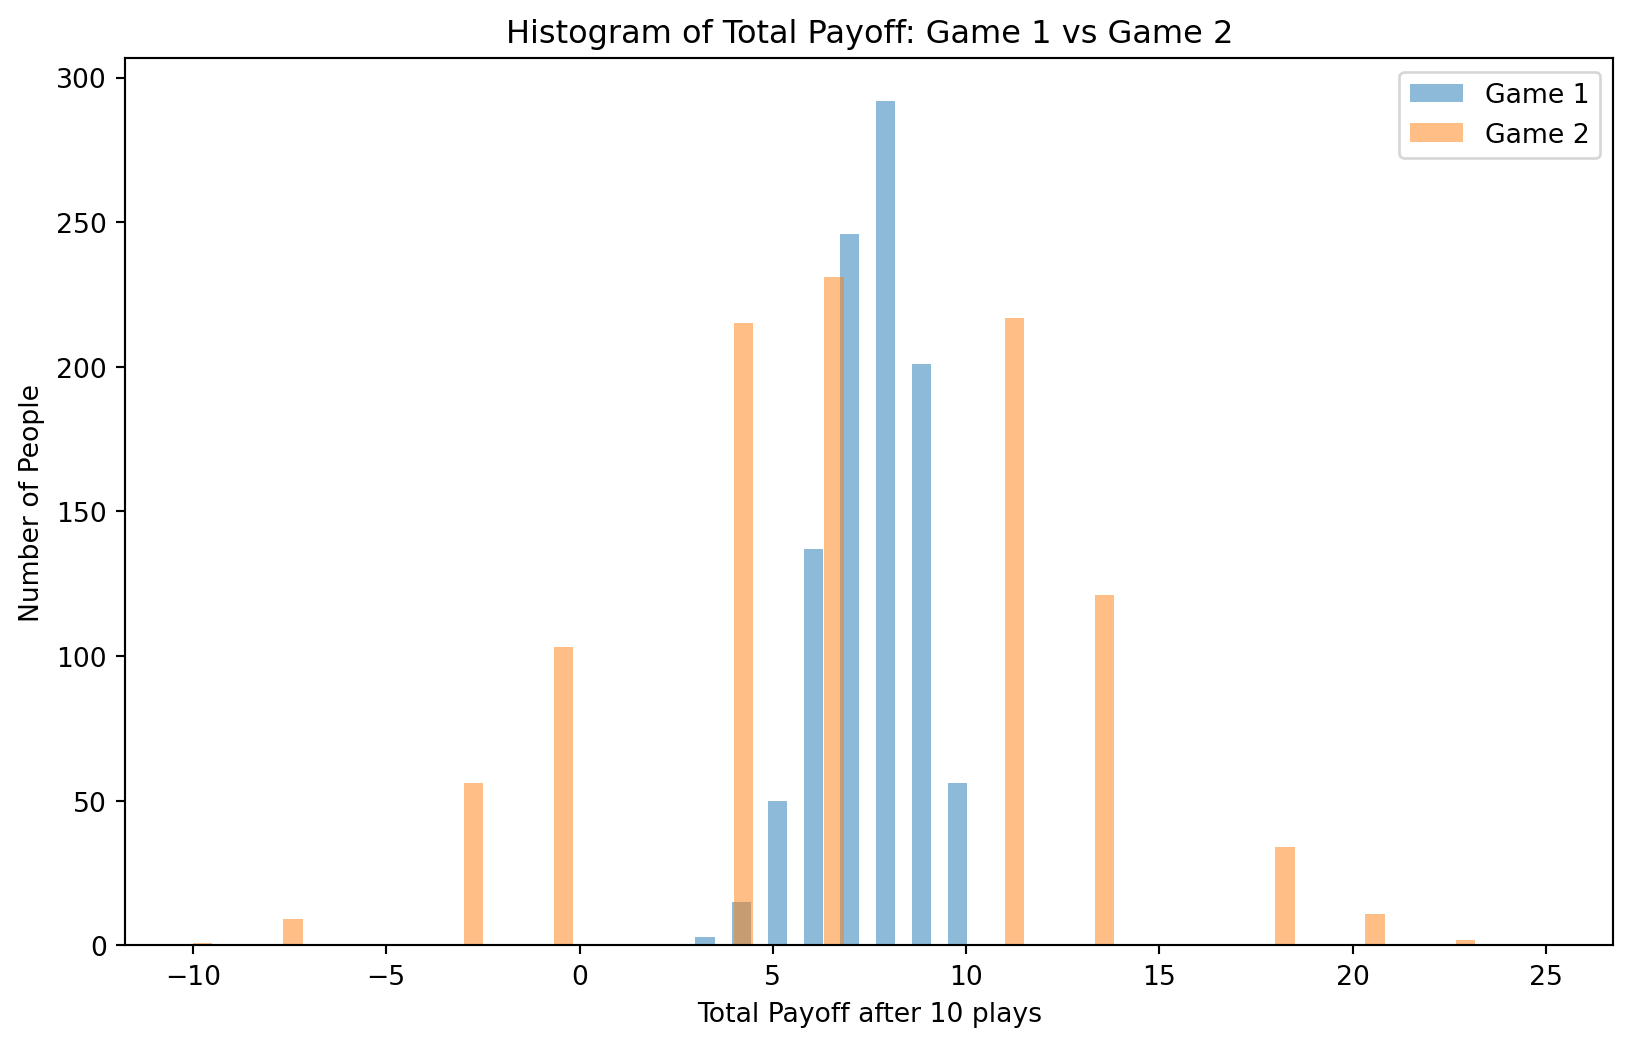

In [11]:
#ex-class

game_1 = np.random.choice([0, 1], size=(10, 1000), p=[0.25, 0.75])
game_2 = np.random.choice([-1, 2.5], size=(10, 1000), p=[0.5, 0.5])

df = pd.DataFrame({
    'game_1': game_1.sum(axis=0),
    'game_2': game_2.sum(axis=0)
})
df.head()

# Plot the histogram of the results
plt.figure(figsize=(10, 6))
plt.hist(df['game_1'], bins=15, alpha=0.5, label='Game 1', width=0.5)
plt.hist(df['game_2'], bins=15, alpha=0.5, label='Game 2', width=0.5)
plt.xlabel('Total Payoff after 10 plays')
plt.ylabel('Number of People')
plt.title('Histogram of Total Payoff: Game 1 vs Game 2')
plt.legend()
plt.show()


:::{#ex-variance .ex-class}
## Variance

1. Compute the variance and the standard deviation of both games from the previous exercise.
2. Let's say that you are pricing the ticket for both games at 1 EUR. What are your expected profits in both cases? What is the standard deviation of your profits?

:::

## Cumulative Distribution Function

The probability mass function (PMF) of a random variable $X$ gives the probability of each possible value of $X$. The cumulative distribution function (CDF) of $X$ gives the probability that $X$ is less than or equal to a given value $x$.

:::{#def-cdf .ex-class}
## Cumulative Distribution Function

For a discrete random variable $X$, the cumulative distribution function (CDF) is defined as

$$
F(x) = P(X \leq x) = \sum_{k \leq x} f(k)
$$

where $f(x)$ is the PMF of $X$. The notation in the sum index is a condition. Instead of explicitly writing the numbers of the elements like in $\sum_{i=1}^{3}$ we can also write a condition that describes which indices are included in the sum, i.e. $\sum_{0 \leq i \leq 3}$
means the same as $\sum_{i=0}^{3}$.

:::

:::{#exr-cdf .ex-class}
## Properties of the CDF

Consider a discrete random variable $X$ with PMF $f(x)$ and CDF $F(x)$. Show that the CDF satisfies the following properties:

1. $F(x)$ is non-decreasing.
2. $F(x) \in [0, 1]$ for all $x$.
3. $\lim_{x \to -\infty} F(x) = 0$ and $\lim_{x \to \infty} F(x) = 1$.
4. $P(a < X \leq b) = F(b) - F(a)$ for all $a < b$.
5. $P(X = a) = F(a) - F(a - 1)$ for all $a$.
:::

:::{#exr-cdf-coins .ex-class}
## CDF of the Coin Tossing Game

Consider our introductory example of the coin tossing game where you win 2 EUR for every head. Write down the CDF of the random variable $X$ that counts the amount of money you win and use it to calculate the following probabilities:

1. The probability of winning between 1.5 and 3 EUR (inclusive).
2. The probability to win more than 2.5 EUR.
3. The probability of winning between 2 and 6 EUR (inclusive).

:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

The PMF of $X$ is

$$
f(x) = \begin{cases}
\frac{1}{4} & \text{if } x = 0 \\
\frac{1}{2} & \text{if } x = 2 \\
\frac{1}{4} & \text{if } x = 4 \\
0 & \text{otherwise}
\end{cases}
$$

The CDF of $X$ is

$$
F(x) = \sum_{y \leq x} f(y)
$$

$$
F(x) = \begin{cases}
0 & \text{if } x < 0 \\
\frac{1}{4} & \text{if } 0 \leq x < 2 \\
\frac{3}{4} & \text{if } 2 \leq x < 4 \\
1 & \text{if } x \geq 4
\end{cases}
$$

The probability of winning between 1.5 and 3 EUR is

$$
P(1.5 \leq X \leq 3) = F(3) - F(1.5) + P(X = 1.5) = \frac{3}{4} - \frac{1}{4} + 0 = \frac{1}{2}
$$

The probability of winning more than 2.5 EUR is

$$
P(X > 2.5) = 1 - P(X \leq 2.5) = 1 - F(2.5) = 1 - \frac{3}{4} = \frac{1}{4}
$$

The probability of winning between 2 and 6 EUR is

$$
P(2 \leq X \leq 6) = F(6) - F(2) + P(X = 2) = 1 - \frac{3}{4} + 0 = \frac{1}{4}
$$


:::

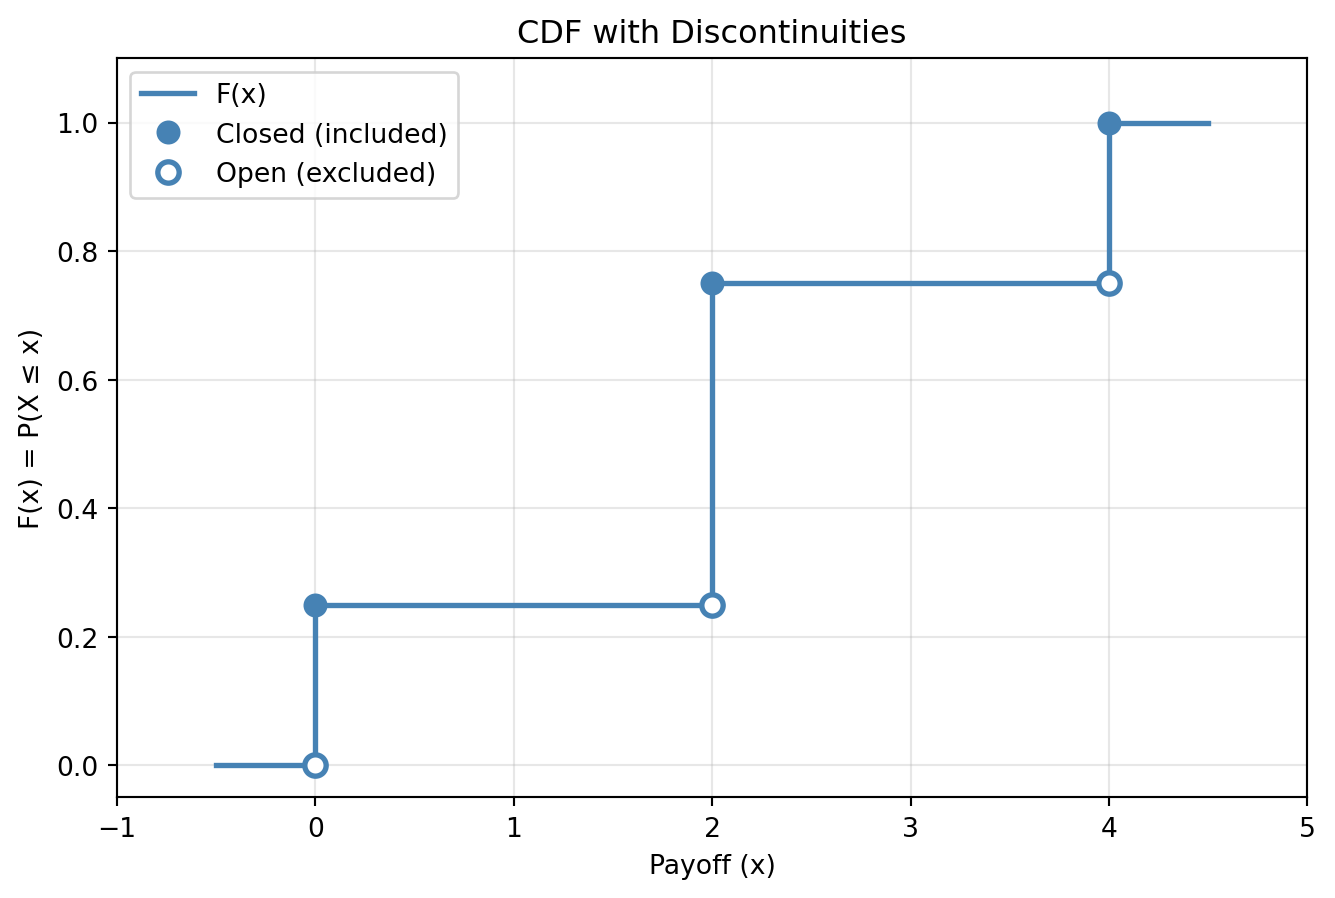

In [12]:
#| label: fig-coins-cdf-plot
#| fig-cap: Plot of the cumulative distribution function of the payoff of the coin game.

# Define CDF values - the CDF jumps at each payoff value
x_values = [-0.5, 0, 2, 4, 4.5]  # Extended range for visualization
cdf_values = [0, 0.25, 0.75, 1.0, 1.0]

plt.figure(figsize=(8, 5))

# Plot step function (right-continuous, as CDFs should be)
plt.step(x_values, cdf_values, where='post', linewidth=2, color='steelblue', label='F(x)')

# Add filled markers at the start of each step (closed intervals)
jump_points_x = [0, 2, 4]
jump_points_y = [0.25, 0.75, 1.0]
plt.plot(jump_points_x, jump_points_y, 'o', markersize=8, label='Closed (included)', color='steelblue')

# Add empty markers at the end of each step (open intervals)
end_points_x = [0, 2, 4]
end_points_y = [0, 0.25, 0.75]
plt.plot(end_points_x, end_points_y, 'wo', markeredgecolor='steelblue', 
         markersize=8, markeredgewidth=2, label='Open (excluded)')

plt.xlabel('Payoff (x)')
plt.ylabel('F(x) = P(X ≤ x)')
plt.title('CDF with Discontinuities')
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.1)
plt.xlim(-1, 5)
plt.legend()

## Exercises

### Exercise 1 (Expected Value - Game Strategy)

In a game similar to "Who Wants to Be a Millionaire?", a contestant is asked a series of multiple-choice questions. For simplicity we will limit the number of questions to two. Furthermore, the participant has a 70% chance of answering question A correctly and a 50% chance of answering question B. The rewards are 100 USD for a correct answer to question A and 300 USD for a correct answer to question B. Assume that the answers to the two questions are independent. If the contestant gives a wrong answer to any of the questions, the game ends immediately and no further questions are asked. The participant keeps the money won up to that point. The contestant can choose the order in which to answer the questions. What is the optimal order to maximize the expected winnings?



### Exercise (CDF)

You are allowed to take a test three times. On each attempt, you are equally likely to score any integer number of points between 1 and 10 (inclusive). Your final score is the maximum score you achieved on any of the three attempts. What is the PMF of your final score?





### Exercise 2 (St. Petersburg Paradox)

You are offered to play the following game: A fair coin is tossed repeatedly until it comes up heads. If the first head appears on the n-th toss, you win $2^n$ EUR. How much would you be willing to pay to play this game?
